# Dataset creation - Group 44
Goal: binary classification of `RainTomorrow` (>= 1.0 mm precipitation on the next day).

Steps: (1) load and look at the data, (2) prior distributions, (3) relationships between features,
(4) data quality, (5) feature preparation, (6) save `data/processed/final_dataset.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/processed/dataset_with_target.csv", parse_dates=["date"])
print("Dataset shape:", df.shape)
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())
df.info()
df.head()

Dataset shape: (21912, 13)
Date range: 2016-01-01 -> 2025-12-30
<class 'pandas.DataFrame'>
RangeIndex: 21912 entries, 0 to 21911
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   location                     21912 non-null  str           
 1   date                         21912 non-null  datetime64[us]
 2   weather_code                 21912 non-null  int64         
 3   temperature_2m_max           21912 non-null  float64       
 4   temperature_2m_min           21912 non-null  float64       
 5   temperature_2m_mean          21912 non-null  float64       
 6   apparent_temperature_mean    21912 non-null  float64       
 7   precipitation_sum            21912 non-null  float64       
 8   rain_sum                     21912 non-null  float64       
 9   precipitation_hours          21912 non-null  float64       
 10  wind_speed_10m_max           21912 non-null  float64 

,location,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_direction_10m_dominant,RainTomorrow
0,berlin,2016-01-01,51,3.5,-0.3,1.9,-0.9,0.4,0.4,2.0,9.6,243,0
1,berlin,2016-01-02,3,1.7,-6.9,-2.7,-8.3,0.0,0.0,0.0,25.4,96,0
2,berlin,2016-01-03,3,-6.4,-9.9,-8.1,-14.7,0.0,0.0,0.0,23.2,102,0
3,berlin,2016-01-04,3,-3.9,-8.9,-6.7,-12.7,0.0,0.0,0.0,21.4,98,1
4,berlin,2016-01-05,73,-5.3,-7.7,-6.6,-12.3,2.1,0.0,9.0,18.4,82,1


In [2]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,21912,2020-12-30 12:00:00,2016-01-01 00:00:00,2018-07-01 18:00:00,2020-12-30 12:00:00,2023-07-01 06:00:00,2025-12-30 00:00:00,NaN
weather_code,21912.0,33.355194,0.0,3.0,51.0,55.0,75.0,27.390188
temperature_2m_max,21912.0,17.129098,-12.7,10.6,17.5,23.2,42.0,8.246258
temperature_2m_min,21912.0,9.242077,-20.5,3.6,9.3,14.8,29.6,7.479343
temperature_2m_mean,21912.0,13.117931,-14.5,7.1,13.3,18.9,34.9,7.648532
apparent_temperature_mean,21912.0,11.338595,-21.5,3.6,11.2,18.4,38.6,9.722441
precipitation_sum,21912.0,3.229541,0.0,0.0,0.2,2.8,183.6,7.780297
rain_sum,21912.0,3.107576,0.0,0.0,0.2,2.6,183.6,7.667177
precipitation_hours,21912.0,4.431134,0.0,0.0,1.0,7.0,24.0,5.980038
wind_speed_10m_max,21912.0,20.485556,3.5,14.7,19.1,24.8,95.9,8.147518


## 1. Prior probabilities

Why: before modelling we want to know how the target and a few features are distributed on their own
(no conditioning on anything else), and whether the classes are balanced.

Helper columns used only for readable plots: a compass name for the wind direction and a grouped weather
code (WMO codes are numbers with no obvious meaning, so we group them into 8 weather types).

In [3]:
WEATHER_GROUPS = {
    "clear": [0, 1],
    "cloudy": [2, 3],
    "fog": [45, 48],
    "drizzle": [51, 53, 55, 56, 57],
    "rain": [61, 63, 65, 66, 67],
    "snow": [71, 73, 75, 77, 85, 86],
    "showers": [80, 81, 82],
    "thunderstorm": [95, 96, 99],
}
GROUP_ORDER = list(WEATHER_GROUPS)
CODE_TO_GROUP = {code: group for group, codes in WEATHER_GROUPS.items() for code in codes}

COMPASS = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]

def weather_group(codes):
    return codes.map(CODE_TO_GROUP).fillna("other")

def wind_sector(degrees):
    idx = (((degrees + 22.5) % 360) // 45).astype(int)
    return idx.map(dict(enumerate(COMPASS)))

df["weather_group"] = weather_group(df["weather_code"])
df["wind_sector"] = wind_sector(df["wind_direction_10m_dominant"])

print("Weather codes that are not in the mapping:", (df["weather_group"] == "other").sum())
print("Codes in the data:", sorted(df["weather_code"].unique().tolist()))

Weather codes that are not in the mapping: 0
Codes in the data: [0, 1, 2, 3, 51, 53, 55, 61, 63, 65, 71, 73, 75]


In [4]:
target_counts = df["RainTomorrow"].value_counts().sort_index()
print("RainTomorrow counts:")
print(target_counts)
print("\nRainTomorrow percentages:")
print((df["RainTomorrow"].value_counts(normalize=True).sort_index() * 100).round(2))
print("\nRows per location:")
print(df["location"].value_counts())

RainTomorrow counts:
RainTomorrow
0    13827
1     8085
Name: count, dtype: int64

RainTomorrow percentages:
RainTomorrow
0    63.1
1    36.9
Name: proportion, dtype: float64

Rows per location:
location
berlin       3652
london       3652
new_york     3652
sydney       3652
tokyo        3652
vancouver    3652
Name: count, dtype: int64


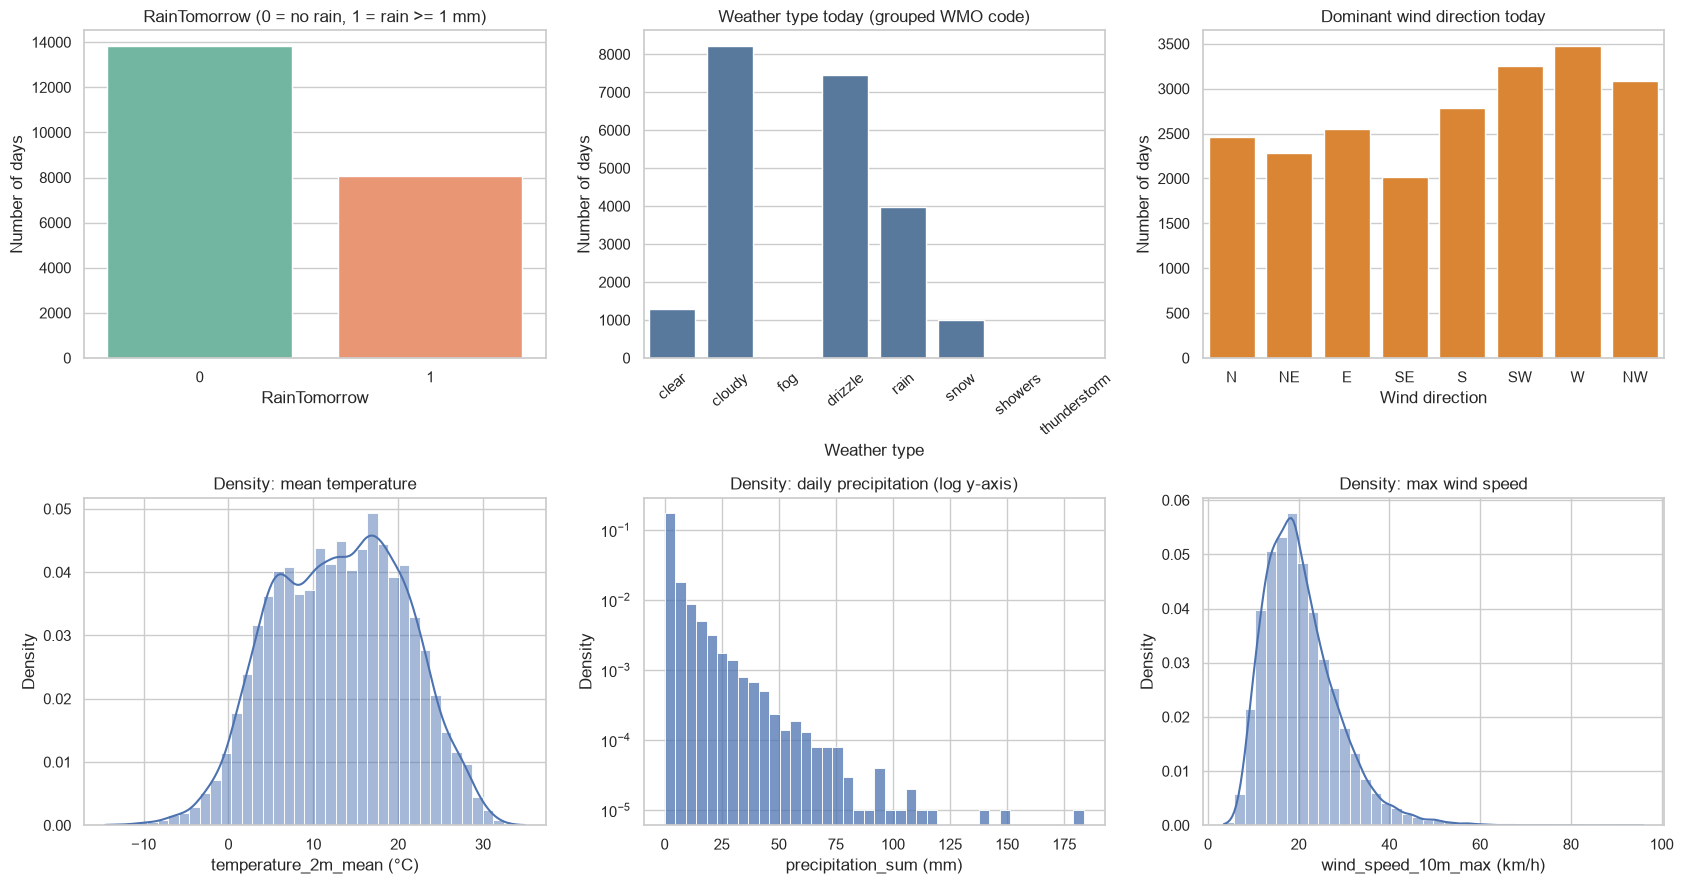

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

# target
sns.countplot(data=df, x="RainTomorrow", hue="RainTomorrow", legend=False,
              palette="Set2", ax=axes[0, 0])
axes[0, 0].set_title("RainTomorrow (0 = no rain, 1 = rain >= 1 mm)")
axes[0, 0].set_xlabel("RainTomorrow")
axes[0, 0].set_ylabel("Number of days")

# categorical 1: weather type today
sns.countplot(data=df, x="weather_group", order=GROUP_ORDER, color="#4c78a8", ax=axes[0, 1])
axes[0, 1].set_title("Weather type today (grouped WMO code)")
axes[0, 1].set_xlabel("Weather type")
axes[0, 1].set_ylabel("Number of days")
axes[0, 1].tick_params(axis="x", rotation=40)

# categorical 2: dominant wind direction
sns.countplot(data=df, x="wind_sector", order=COMPASS, color="#f58518", ax=axes[0, 2])
axes[0, 2].set_title("Dominant wind direction today")
axes[0, 2].set_xlabel("Wind direction")
axes[0, 2].set_ylabel("Number of days")

# continuous variables (density)
sns.histplot(df["temperature_2m_mean"], bins=40, kde=True, stat="density", ax=axes[1, 0])
axes[1, 0].set_title("Density: mean temperature")
axes[1, 0].set_xlabel("temperature_2m_mean (°C)")

sns.histplot(df["precipitation_sum"], bins=40, stat="density", ax=axes[1, 1])
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Density: daily precipitation (log y-axis)")
axes[1, 1].set_xlabel("precipitation_sum (mm)")

sns.histplot(df["wind_speed_10m_max"], bins=40, kde=True, stat="density", ax=axes[1, 2])
axes[1, 2].set_title("Density: max wind speed")
axes[1, 2].set_xlabel("wind_speed_10m_max (km/h)")

for ax in axes[1]:
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

**What we see / what it means:**
- 63% of days are followed by a dry day and 37% by a rainy day, so there are more dry days than rainy days. The imbalance is not extreme. A model that always predicts "no rain" would already be right 63% of the time, so later we should not judge models by accuracy alone.
- The share of rainy days is realistic for these cities: from 34% (Berlin, Sydney) to 44% (Vancouver, the rainiest).
- `precipitation_sum` is very skewed: 43% of days have exactly 0 mm and the median is only 0.2 mm, but a few days have very heavy rain (up to 183.6 mm). This pulls the mean up to 3.2 mm, so the mean is not a good summary. That is why we use a log scale in the plot.
- Every city has the same number of rows (3,652) because we downloaded the same 10 years for each city. This comes from how we collected the data, not from the weather itself.


## 2. Relationships between features

Why: to find features that are (a) almost duplicates of each other and (b) related to tomorrow's rain.

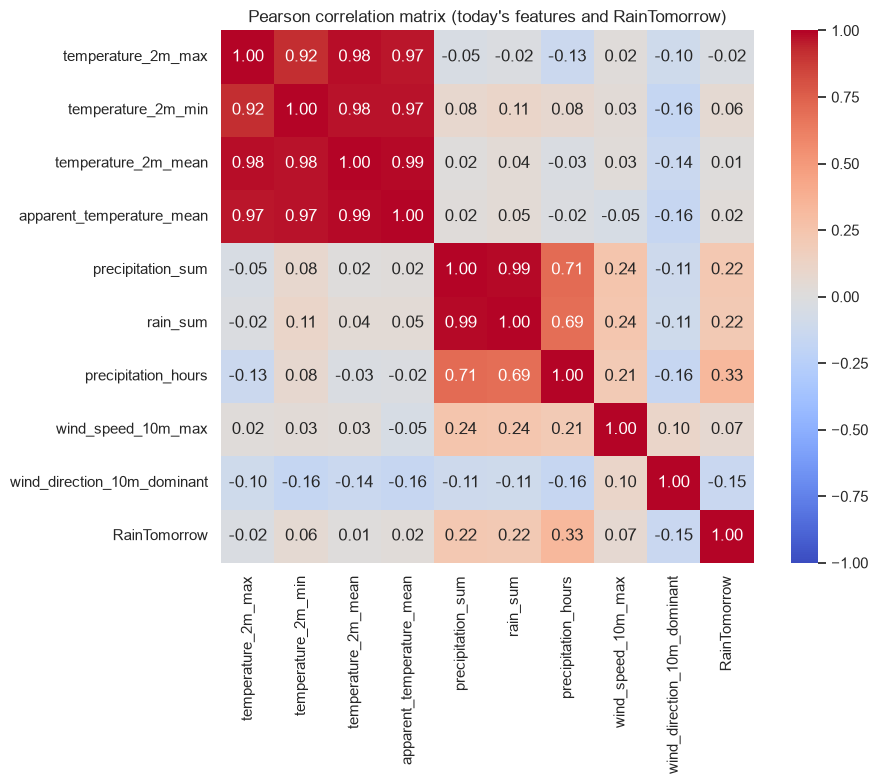

In [6]:
num_cols = [
    "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
    "apparent_temperature_mean", "precipitation_sum", "rain_sum",
    "precipitation_hours", "wind_speed_10m_max", "wind_direction_10m_dominant",
    "RainTomorrow",
]

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Pearson correlation matrix (today's features and RainTomorrow)")
plt.tight_layout()
plt.show()

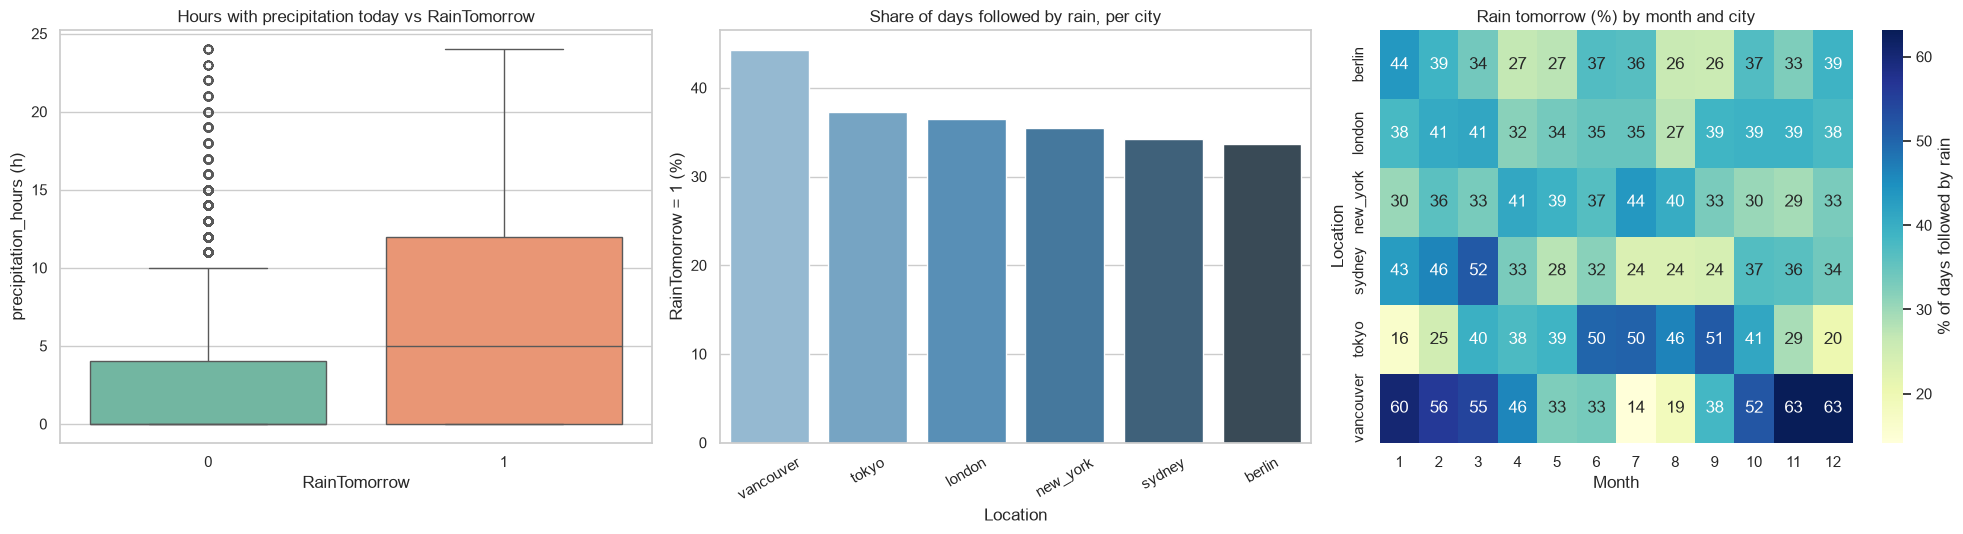

In [7]:
df["month"] = df["date"].dt.month

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# 1. hours of rain today vs rain tomorrow
sns.boxplot(data=df, x="RainTomorrow", y="precipitation_hours", hue="RainTomorrow",
            legend=False, palette="Set2", ax=axes[0])
axes[0].set_title("Hours with precipitation today vs RainTomorrow")
axes[0].set_xlabel("RainTomorrow")
axes[0].set_ylabel("precipitation_hours (h)")

# 2. share of rainy tomorrows per city
city_rain = (df.groupby("location")["RainTomorrow"].mean() * 100).sort_values(ascending=False)
sns.barplot(x=city_rain.index, y=city_rain.values, hue=city_rain.index, legend=False,
            palette="Blues_d", ax=axes[1])
axes[1].set_title("Share of days followed by rain, per city")
axes[1].set_xlabel("Location")
axes[1].set_ylabel("RainTomorrow = 1 (%)")
axes[1].tick_params(axis="x", rotation=30)

# 3. month x city
month_city = df.pivot_table(index="location", columns="month",
                            values="RainTomorrow", aggfunc="mean") * 100
sns.heatmap(month_city, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label": "% of days followed by rain"}, ax=axes[2])
axes[2].set_title("Rain tomorrow (%) by month and city")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Location")

plt.tight_layout()
plt.show()

In [8]:
# Wind direction has a correlation of about -0.15 with RainTomorrow overall.
# Is that real, or just a difference between cities? Check inside each city.
def wind_corr(g):
    return g["wind_direction_10m_dominant"].corr(g["RainTomorrow"])

print("Correlation wind direction vs RainTomorrow, per city:")
print(df.groupby("location")[["wind_direction_10m_dominant", "RainTomorrow"]]
        .apply(wind_corr).round(3))

print("\nShare of rainy tomorrows by wind direction (all cities):")
print((df.groupby("wind_sector")["RainTomorrow"].mean().reindex(COMPASS) * 100).round(1))

Correlation wind direction vs RainTomorrow, per city:
location
berlin       0.047
london       0.070
new_york    -0.234
sydney      -0.140
tokyo       -0.178
vancouver   -0.382
dtype: float64

Share of rainy tomorrows by wind direction (all cities):
wind_sector
N     29.8
NE    35.4
E     52.5
SE    48.1
S     48.3
SW    41.2
W     27.1
NW    19.5
Name: RainTomorrow, dtype: float64


**What we see / what it means:**
- The four temperature columns carry almost the same information (correlation 0.92–0.99), and so do `precipitation_sum` and `rain_sum` (0.99). Keeping all of them adds little new information, so in section 4 we drop some of them.
- `precipitation_hours` has the strongest link with tomorrow's rain (correlation 0.33). Rainy weather often lasts more than one day, so many hours of rain today make rain tomorrow more likely. Temperature on its own has almost no link with tomorrow's rain (about 0).
- Rain depends on the city and the month. Vancouver is the rainiest city (44% of days are followed by rain) and is wettest in winter (about 60% in Nov–Jan) and driest in summer (14% in July). Tokyo is the opposite: wettest in summer (about 50% in Jun–Sep) and driest in winter (16% in January). Sydney is wettest in Feb–Mar and driest in Jul–Sep. So `location` and `month` are useful features.
- Wind direction has a correlation of −0.15 with tomorrow's rain overall, but it differs between cities: strong in Vancouver (−0.38) and New York (−0.23), close to zero in London and Berlin. Easterly and southerly winds are followed by rain about half the time, northwest winds only about 20% of the time. Because wind direction is a circle (0° and 360° are the same), we turn it into sin/cos features in section 4.


## 3. Data quality

Why: the model can only be as good as the data. We check missing values, duplicates, gaps in time and
values that are physically impossible or inconsistent.

In [9]:
print("Missing values per column:")
print(df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else "none")
print("\nDuplicated (location, date):", df.duplicated(subset=["location", "date"]).sum())
print("Days per location:", df.groupby("location").size().unique())

gaps = df.sort_values(["location", "date"]).groupby("location")["date"].diff().dropna()
print("Gaps in dates:", (gaps != pd.Timedelta(days=1)).sum())

Missing values per column:
none

Duplicated (location, date): 0
Days per location: [3652]
Gaps in dates: 0


In [10]:
checks = {
    "temp order (min <= mean <= max) violated":
        (df["temperature_2m_min"] > df["temperature_2m_mean"]) | (df["temperature_2m_mean"] > df["temperature_2m_max"]),
    "negative precipitation / rain / hours":
        (df["precipitation_sum"] < 0) | (df["rain_sum"] < 0) | (df["precipitation_hours"] < 0),
    "precipitation_hours > 24":
        df["precipitation_hours"] > 24,
    "rain_sum > precipitation_sum":
        df["rain_sum"] > df["precipitation_sum"] + 1e-6,
    "negative wind speed":
        df["wind_speed_10m_max"] < 0,
    "wind direction outside 0-360":
        (df["wind_direction_10m_dominant"] < 0) | (df["wind_direction_10m_dominant"] > 360),
    "precipitation hours > 0 but 0 mm":
        (df["precipitation_hours"] > 0) & (df["precipitation_sum"] == 0),
    "mm > 0 but 0 precipitation hours":
        (df["precipitation_sum"] > 0) & (df["precipitation_hours"] == 0),
    "weather code not in the WMO list we know":
        df["weather_group"] == "other",
}
quality = pd.Series({name: int(mask.sum()) for name, mask in checks.items()},
                    name="number of rows")
quality

temp order (min <= mean <= max) violated    0
negative precipitation / rain / hours       0
precipitation_hours > 24                    0
rain_sum > precipitation_sum                0
negative wind speed                         0
wind direction outside 0-360                0
precipitation hours > 0 but 0 mm            0
mm > 0 but 0 precipitation hours            0
weather code not in the WMO list we know    0
Name: number of rows, dtype: int64

In [11]:
# Rain codes (drizzle/rain/showers/snow/thunderstorm) on a day with almost no precipitation?
rainy_codes = df["weather_group"].isin(["drizzle", "rain", "snow", "showers", "thunderstorm"])
print("Rain-type weather code but precipitation_sum < 0.1 mm:",
      int((rainy_codes & (df["precipitation_sum"] < 0.1)).sum()))
print("Clear/cloudy/fog code but precipitation_sum >= 1 mm:",
      int((~rainy_codes & (df["precipitation_sum"] >= 1)).sum()))

Rain-type weather code but precipitation_sum < 0.1 mm: 7
Clear/cloudy/fog code but precipitation_sum >= 1 mm: 0


**What we see / what it means:**
- There are no missing values, no duplicate rows (same city and date) and no missing days. So we did not need to fill in any values or remove any rows.
- All consistency checks found 0 problems. For example, the minimum temperature is never above the maximum, rain is never more than total precipitation, and precipitation hours are always between 0 and 24.
- All weather codes are valid codes. Only 13 different codes appear in the data, and there are no fog or thunderstorm days.
- The only small issue is that 7 days have a rain-type weather code but less than 0.1 mm of precipitation. That is 7 out of 21,912 days, too few to matter, so we kept these rows.
- Conclusion: the data is clean, so no rows were removed or changed.


## 4. Data preparation

Decisions (each one is justified by the plots / numbers above):

| Action | Why |
|---|---|
| `temp_range = max - min` | size of the daily swing; cloudy/rainy days usually have a smaller range |
| `apparent_temp_diff = apparent_mean - mean` | wind chill / humidity effect without repeating the temperature |
| `non_rain_precip = precipitation_sum - rain_sum` | mostly snow, which `rain_sum` does not include |
| drop `rain_sum` | `precipitation_sum` and `rain_sum` have corr 0.99, and `rain_sum` = `precipitation_sum` - `non_rain_precip` |
| drop `temperature_2m_max/min`, `apparent_temperature_mean` | corr 0.92-0.99 with `temperature_2m_mean`; their information is kept by `temp_range` and `apparent_temp_diff` |
| `wind_dir_sin/cos` instead of degrees | 359° and 1° are neighbours, a plain number would treat them as far apart |
| `month_sin/cos` instead of month | December and January are neighbours; keeps the season information |
| `weather_group` instead of `weather_code` | discretization: 28 numeric codes -> 8 weather types |

`date` and `location` stay in the file so Part B can split by time and encode the city.

In [12]:
def add_features(raw):
    out = raw.copy()

    out["temp_range"] = out["temperature_2m_max"] - out["temperature_2m_min"]
    out["apparent_temp_diff"] = out["apparent_temperature_mean"] - out["temperature_2m_mean"]
    out["non_rain_precip"] = (out["precipitation_sum"] - out["rain_sum"]).clip(lower=0)

    angle = np.deg2rad(out["wind_direction_10m_dominant"])
    out["wind_dir_sin"] = np.sin(angle)
    out["wind_dir_cos"] = np.cos(angle)

    month = out["date"].dt.month
    out["month_sin"] = np.sin(2 * np.pi * month / 12)
    out["month_cos"] = np.cos(2 * np.pi * month / 12)

    out["weather_group"] = weather_group(out["weather_code"])

    drop_cols = [
        "rain_sum", "temperature_2m_max", "temperature_2m_min",
        "apparent_temperature_mean", "wind_direction_10m_dominant", "weather_code",
    ]
    return out.drop(columns=drop_cols)


base = df.drop(columns=["weather_group", "wind_sector", "month"])   # helper columns from the plots
final_df = add_features(base)

# keep the target as the last column
final_df = final_df[[c for c in final_df.columns if c != "RainTomorrow"] + ["RainTomorrow"]]

print("Before:", base.shape, " After:", final_df.shape)
print("Missing values after preparation:", int(final_df.isna().sum().sum()))
final_df.head()

Before: (21912, 13)  After: (21912, 15)
Missing values after preparation: 0


,location,date,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,temp_range,apparent_temp_diff,non_rain_precip,wind_dir_sin,wind_dir_cos,month_sin,month_cos,weather_group,RainTomorrow
0,berlin,2016-01-01,1.9,0.4,2.0,9.6,3.8,-2.8,0.0,-0.891007,-0.453990,0.5,0.866025,drizzle,0
1,berlin,2016-01-02,-2.7,0.0,0.0,25.4,8.6,-5.6,0.0,0.994522,-0.104528,0.5,0.866025,cloudy,0
2,berlin,2016-01-03,-8.1,0.0,0.0,23.2,3.5,-6.6,0.0,0.978148,-0.207912,0.5,0.866025,cloudy,0
3,berlin,2016-01-04,-6.7,0.0,0.0,21.4,5.0,-6.0,0.0,0.990268,-0.139173,0.5,0.866025,cloudy,1
4,berlin,2016-01-05,-6.6,2.1,9.0,18.4,2.4,-5.7,2.1,0.990268,0.139173,0.5,0.866025,snow,1


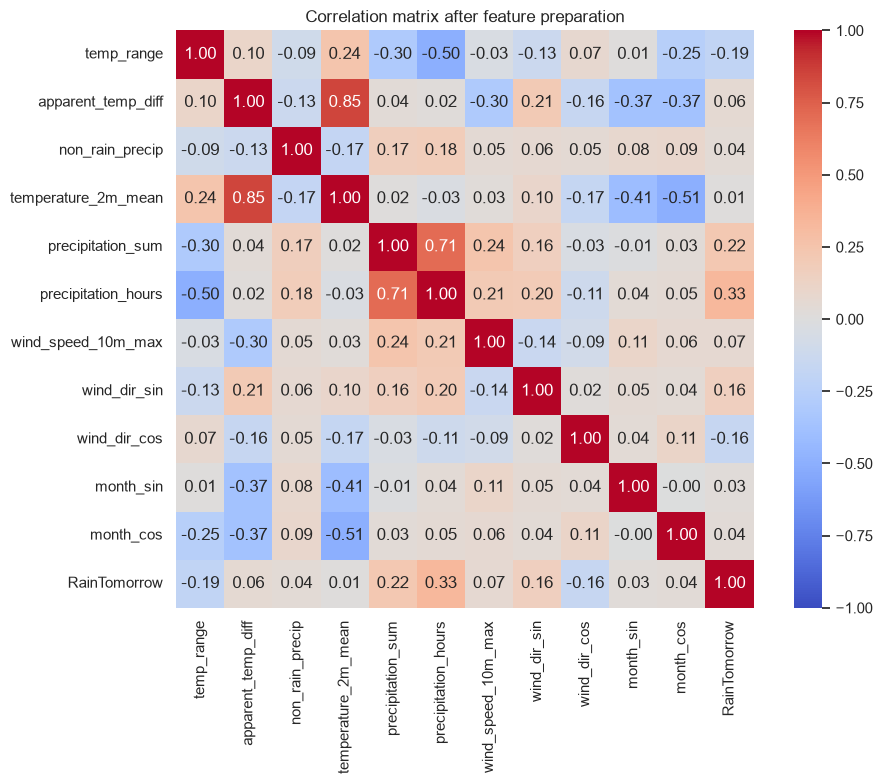

In [13]:
# did the new features keep a relation to the target?
new_num = ["temp_range", "apparent_temp_diff", "non_rain_precip", "temperature_2m_mean",
           "precipitation_sum", "precipitation_hours", "wind_speed_10m_max",
           "wind_dir_sin", "wind_dir_cos", "month_sin", "month_cos", "RainTomorrow"]
plt.figure(figsize=(10, 8))
sns.heatmap(final_df[new_num].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix after feature preparation")
plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)
final_df.to_csv("data/processed/final_dataset.csv", index=False)
print("Saved data/processed/final_dataset.csv, shape:", final_df.shape)
print("Columns:", list(final_df.columns))

Saved data/processed/final_dataset.csv, shape: (21912, 15)
Columns: ['location', 'date', 'temperature_2m_mean', 'precipitation_sum', 'precipitation_hours', 'wind_speed_10m_max', 'temp_range', 'apparent_temp_diff', 'non_rain_precip', 'wind_dir_sin', 'wind_dir_cos', 'month_sin', 'month_cos', 'weather_group', 'RainTomorrow']
